# YOLOv4-tiny on a custom dataset (Darknet) + full evaluation report

Run the cells **top to bottom**. Before you start: `Runtime > Change runtime type > GPU`.

What you get in `/content/runs/all_files` (zipped and downloaded by the last cell):

| File | What it is |
|---|---|
| `best.weights`, `last.weights` | Trained model (darknet format) |
| `custom-yolov4-tiny-detector.cfg`, `obj.data`, `obj.names` | Needed to use the weights |
| `PR_curve.png`, `F1_curve.png`, `P_curve.png`, `R_curve.png` | Curves |
| `confusion_matrix.png`, `confusion_matrix_normalized.png` | Confusion matrices |
| `metrics_per_class.csv`, `metrics.json` | Precision, recall, mAP50, mAP50-95 |
| `training_chart.png`, `darknet_map_report.txt` | Darknet's own loss/mAP chart and report |

**About `.pt` files:** darknet saves `.weights`, not PyTorch `.pt`. `best.pt` / `last.pt` only exist when training with PyTorch frameworks such as Ultralytics.

## 1. Detect GPU

In [1]:
import subprocess
try:
    cc = subprocess.check_output(
        ['nvidia-smi', '--query-gpu=compute_cap', '--format=csv,noheader']
    ).decode().strip().split('\n')[0]
except Exception:
    raise RuntimeError("No GPU found. Runtime > Change runtime type > select a GPU, then rerun.")

cc_num = cc.replace('.', '')
arch = f"-gencode arch=compute_{cc_num},code=[sm_{cc_num},compute_{cc_num}]"
cudnn_half = 1 if float(cc) >= 7.0 else 0
print("Compute capability:", cc, "| ARCH:", arch, "| CUDNN_HALF:", cudnn_half)

Compute capability: 7.5 | ARCH: -gencode arch=compute_75,code=[sm_75,compute_75] | CUDNN_HALF: 1


## 2. Clone and build darknet

**Warning:** this deletes `/content/darknet` (including `backup/`). If you have weights there, copy them out first.

In [2]:
%cd /content
!rm -rf darknet
!git clone https://github.com/AlexeyAB/darknet.git
!apt-get -qq update
!apt-get -qq install -y libopencv-dev

import subprocess, os
has_cv = subprocess.call('pkg-config --exists opencv4 || pkg-config --exists opencv', shell=True) == 0
opencv_flag = 1 if has_cv else 0
print("OpenCV found:", has_cv)
if not has_cv:
    print("WARNING: building without OpenCV. Training still works, but mosaic augmentation and the loss chart are disabled.")

%cd /content/darknet
!sed -i 's/^OPENCV=0/OPENCV={opencv_flag}/' Makefile
!sed -i 's/^GPU=0/GPU=1/' Makefile
!sed -i 's/^CUDNN=0/CUDNN=1/' Makefile
!sed -i 's/^CUDNN_HALF=0/CUDNN_HALF={cudnn_half}/' Makefile
!make -j4 ARCH="{arch}" 2>&1 | tail -n 25

assert os.path.exists('/content/darknet/darknet'), "Build failed, see the make output above (if it is a cuDNN error, set CUDNN=0 in the sed line above and rerun)"
print("darknet built OK")

/content
Cloning into 'darknet'...
remote: Enumerating objects: 15941, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 15941 (delta 6), reused 3 (delta 3), pack-reused 15925 (from 2)
Receiving objects: 100% (15941/15941), 14.49 MiB | 19.40 MiB/s, done.
Resolving deltas: 100% (10724/10724), done.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Extracting templates from packages: 100%
Selecting previously unselected package libevdev2:amd64.
(Reading database ... 127332 files and directories currently installed.)
Preparing to unpack .../000-libevdev2_1.13.1+dfsg-1build1_amd64.deb ...
Unpacking libevdev2:amd64 (1.13.1+dfsg-1build1) ...
Selecting previously unselected package at-spi2-common.
Preparing to unpack .../001-at-spi2-common_2.52.0-1build1_all.deb ...
Unpacking at-spi2-common (

In [3]:
%cd /content/darknet
!wget -nc https://github.com/AlexeyAB/darknet/releases/download/darknet_yolo_v4_pre/yolov4-tiny.conv.29

/content/darknet
--2026-10-13 08:40:33--  https://github.com/AlexeyAB/darknet/releases/download/darknet_yolo_v4_pre/yolov4-tiny.conv.29
Resolving github.com (github.com)... 20.29.134.23
Connecting to github.com (github.com)|20.29.134.23|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/75388965/28807d00-3ea4-11eb-97b5-4c846ecd1d05?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-10-13T09%3A32%3A53Z&rscd=attachment%3B+filename%3Dyolov4-tiny.conv.29&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-10-13T08%3A32%3A37Z&ske=2026-10-13T09%3A32%3A53Z&sks=b&skv=2018-11-09&sig=bWKiIf%2BwM9vAE81a1jMpcj0ovOw4B4XVzjfof7D4lDs%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc5MTg4MjYzMywibmJmIjoxNzkxODgwODMzLCJwYXRoIj

## 3. Download dataset from Roboflow

Paste a **new** API key (revoke the old one in Roboflow settings, it was exposed in the earlier notebook).

In [4]:
!pip install -q roboflow
from roboflow import Roboflow

rf = Roboflow(api_key="Gl8JhnrZ9V10NSuIm2PR")
project = rf.workspace("multilayervehicle").project("back-camera-new-gm1lk")
version = project.version(3)
dataset = version.download("darknet")
print(dataset.location)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 112.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.0 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to back-camera-new-3 in darknet:: 100%|██████████| 3361/3361 [00:00<00:00, 12015.80it/s]

/content/darknet/back-camera-new-3


In [5]:
import os, shutil
os.chdir('/content/darknet')

train_dir = dataset.location + '/train'
valid_dir = dataset.location + '/valid'

shutil.copy(train_dir + '/_darknet.labels', 'data/obj.names')
with open('data/obj.names') as f:
    num_classes = sum(1 for line in f if line.strip())

shutil.rmtree('data/obj', ignore_errors=True)
os.makedirs('data/obj', exist_ok=True)
os.makedirs('backup', exist_ok=True)

def copy_split(src, list_file):
    images = []
    for name in os.listdir(src):
        low = name.lower()
        if low.endswith(('.jpg', '.jpeg', '.png')):
            shutil.copy(os.path.join(src, name), 'data/obj/' + name)
            images.append('data/obj/' + name)
        elif low.endswith('.txt'):
            shutil.copy(os.path.join(src, name), 'data/obj/' + name)
    with open(list_file, 'w') as out:
        out.write('\n'.join(images) + '\n')
    return len(images)

n_train = copy_split(train_dir, 'data/train.txt')
n_valid = copy_split(valid_dir, 'data/valid.txt')

with open('data/obj.data', 'w') as out:
    out.write(f'classes = {num_classes}\n')
    out.write('train = data/train.txt\n')
    out.write('valid = data/valid.txt\n')
    out.write('names = data/obj.names\n')
    out.write('backup = backup/\n')

print(f"classes: {num_classes} | train images: {n_train} | valid images: {n_valid}")

classes: 12 | train images: 1467 | valid images: 140


## 4. Build the training config from darknet's official `yolov4-tiny-custom.cfg`

In [6]:
import re
os.chdir('/content/darknet')

epochs = 50
batch = 64
subdivisions = 16   # 64 divides evenly by 16 (24 does not, darknet would silently use 48 images/step)

iters_per_epoch = max(1, n_train // batch)
max_batches = epochs * iters_per_epoch
# darknet's recommended minimum. Delete this line to train exactly `epochs` epochs.
max_batches = max(max_batches, num_classes * 2000, 6000)

steps_str = f"{int(.8 * max_batches)},{int(.9 * max_batches)}"
num_filters = (num_classes + 5) * 3

with open('cfg/yolov4-tiny-custom.cfg') as f:
    cfg = f.read()

cfg, n1 = re.subn(r'^batch\s*=.*$', f'batch={batch}', cfg, count=1, flags=re.M)
cfg, n2 = re.subn(r'^subdivisions\s*=.*$', f'subdivisions={subdivisions}', cfg, count=1, flags=re.M)
cfg, n3 = re.subn(r'^max_batches\s*=.*$', f'max_batches={max_batches}', cfg, flags=re.M)
cfg, n4 = re.subn(r'^steps\s*=.*$', f'steps={steps_str}', cfg, flags=re.M)
cfg, n5 = re.subn(r'^classes\s*=.*$', f'classes={num_classes}', cfg, flags=re.M)
cfg, n6 = re.subn(r'^filters\s*=\s*255\s*$', f'filters={num_filters}', cfg, flags=re.M)
assert (n1, n2, n3, n4, n5, n6) == (1, 1, 1, 1, 2, 2), (n1, n2, n3, n4, n5, n6)

with open('cfg/custom-yolov4-tiny-detector.cfg', 'w') as f:
    f.write(cfg)

print(f"max_batches={max_batches} | steps={steps_str} | filters={num_filters} | classes={num_classes}")

max_batches=24000 | steps=19200,21600 | filters=51 | classes=12


## 5. (Optional, recommended) Save weights to Google Drive

Run this **before** training so a disconnect does not delete your weights.

In [7]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/yolov4_backup
!rm -rf /content/darknet/backup
!ln -s /content/drive/MyDrive/yolov4_backup /content/darknet/backup

Mounted at /content/drive


## 6. Train

To resume after a disconnect, replace `yolov4-tiny.conv.29` with `backup/custom-yolov4-tiny-detector_last.weights`.

If you already have trained weights, skip this cell and place them in `backup/` named `custom-yolov4-tiny-detector_best.weights` (they must match this cfg).

In [8]:
%cd /content/darknet
!./darknet detector train data/obj.data cfg/custom-yolov4-tiny-detector.cfg yolov4-tiny.conv.29 -dont_show -map

Streaming output truncated to the last 5000 lines.
 total_bbox = 2999196, rewritten_bbox = 0.367665 % 
v3 (iou loss, Normalizer: (iou: 0.07, obj: 1.00, cls: 1.00) Region 30 Avg (IOU: 0.901375), count: 7, class_loss = 0.035773, iou_loss = 0.687308, total_loss = 0.723081 
v3 (iou loss, Normalizer: (iou: 0.07, obj: 1.00, cls: 1.00) Region 37 Avg (IOU: 0.889887), count: 6, class_loss = 0.000295, iou_loss = 5.319211, total_loss = 5.319507 
 total_bbox = 2999209, rewritten_bbox = 0.367664 % 
v3 (iou loss, Normalizer: (iou: 0.07, obj: 1.00, cls: 1.00) Region 30 Avg (IOU: 0.934171), count: 3, class_loss = 0.013624, iou_loss = 0.213109, total_loss = 0.226733 
v3 (iou loss, Normalizer: (iou: 0.07, obj: 1.00, cls: 1.00) Region 37 Avg (IOU: 0.823367), count: 2, class_loss = 0.000840, iou_loss = 3.262939, total_loss = 3.263779 
 total_bbox = 2999214, rewritten_bbox = 0.367663 % 
v3 (iou loss, Normalizer: (iou: 0.07, obj: 1.00, cls: 1.00) Region 30 Avg (IOU: 0.914713), count: 3, class_loss = 0.00028

## 7. Collect `best.weights` and `last.weights`

In [9]:
import os, shutil, glob
OUT = '/content/runs/all_files'
os.makedirs(OUT, exist_ok=True)

bk = '/content/darknet/backup'
stem = 'custom-yolov4-tiny-detector'
best_c = [f'{bk}/{stem}_best.weights', f'{bk}/{stem}_final.weights', f'{bk}/{stem}_last.weights']
best_src = next((p for p in best_c if os.path.exists(p)), None)
last_c = [p for p in (f'{bk}/{stem}_final.weights', f'{bk}/{stem}_last.weights', f'{bk}/{stem}_best.weights') if os.path.exists(p)]
last_src = max(last_c, key=os.path.getmtime) if last_c else None

assert best_src, "No weights found in backup/. Train first (Cell 6) or put your weights there."
shutil.copy(best_src, f'{OUT}/best.weights')
shutil.copy(last_src, f'{OUT}/last.weights')
print("best.weights <-", os.path.basename(best_src))
print("last.weights <-", os.path.basename(last_src))

best.weights <- custom-yolov4-tiny-detector_best.weights
last.weights <- custom-yolov4-tiny-detector_last.weights


## 8. Evaluation on the test split

Darknet runs `best.weights` on every test image with a very low confidence threshold (0.001) and saves all detections. The next cell turns them into precision, recall, mAP, curves and confusion matrices.

In [10]:
import os, glob
os.chdir('/content/darknet')

exts = ('.jpg', '.jpeg', '.png')
def list_images(d):
    return sorted(p for p in glob.glob(d + '/*') if p.lower().endswith(exts)) if os.path.isdir(d) else []

eval_split = 'test'
eval_images = list_images(os.path.join(dataset.location, 'test'))
if not eval_images:
    eval_split = 'valid'
    eval_images = list_images(os.path.join(dataset.location, 'valid'))
print(f"evaluating on the '{eval_split}' split: {len(eval_images)} images")

with open('data/eval_list.txt', 'w') as f:
    f.write('\n'.join(os.path.abspath(p) for p in eval_images) + '\n')

!rm -f result.json
!./darknet detector test data/obj.data cfg/custom-yolov4-tiny-detector.cfg {OUT}/best.weights -dont_show -ext_output -thresh 0.001 -out result.json < data/eval_list.txt > eval_stdout.txt 2>&1

assert os.path.exists('result.json'), "result.json was not created, see: !tail -n 30 /content/darknet/eval_stdout.txt"
print("result.json size:", os.path.getsize('result.json'), "bytes")

evaluating on the 'test' split: 71 images
result.json size: 95374 bytes


ground-truth boxes per class: {'2-wheelers': 49, 'bus': 1, 'cargo van': 12, 'jeep': 2, 'minibus': 2, 'person': 10, 'sedan': 15, 'suv': 39, 'tricycle': 18, 'truck': 0, 'utility vehicle': 10, 'van': 38}
{
  "split": "test",
  "images": 71,
  "operating_confidence": 0.333,
  "precision": 0.7217445442437511,
  "recall": 0.5971124210342276,
  "f1": 0.6080249817787576,
  "mAP50": 0.664319443492882,
  "mAP50-95": 0.3807017683747956
}


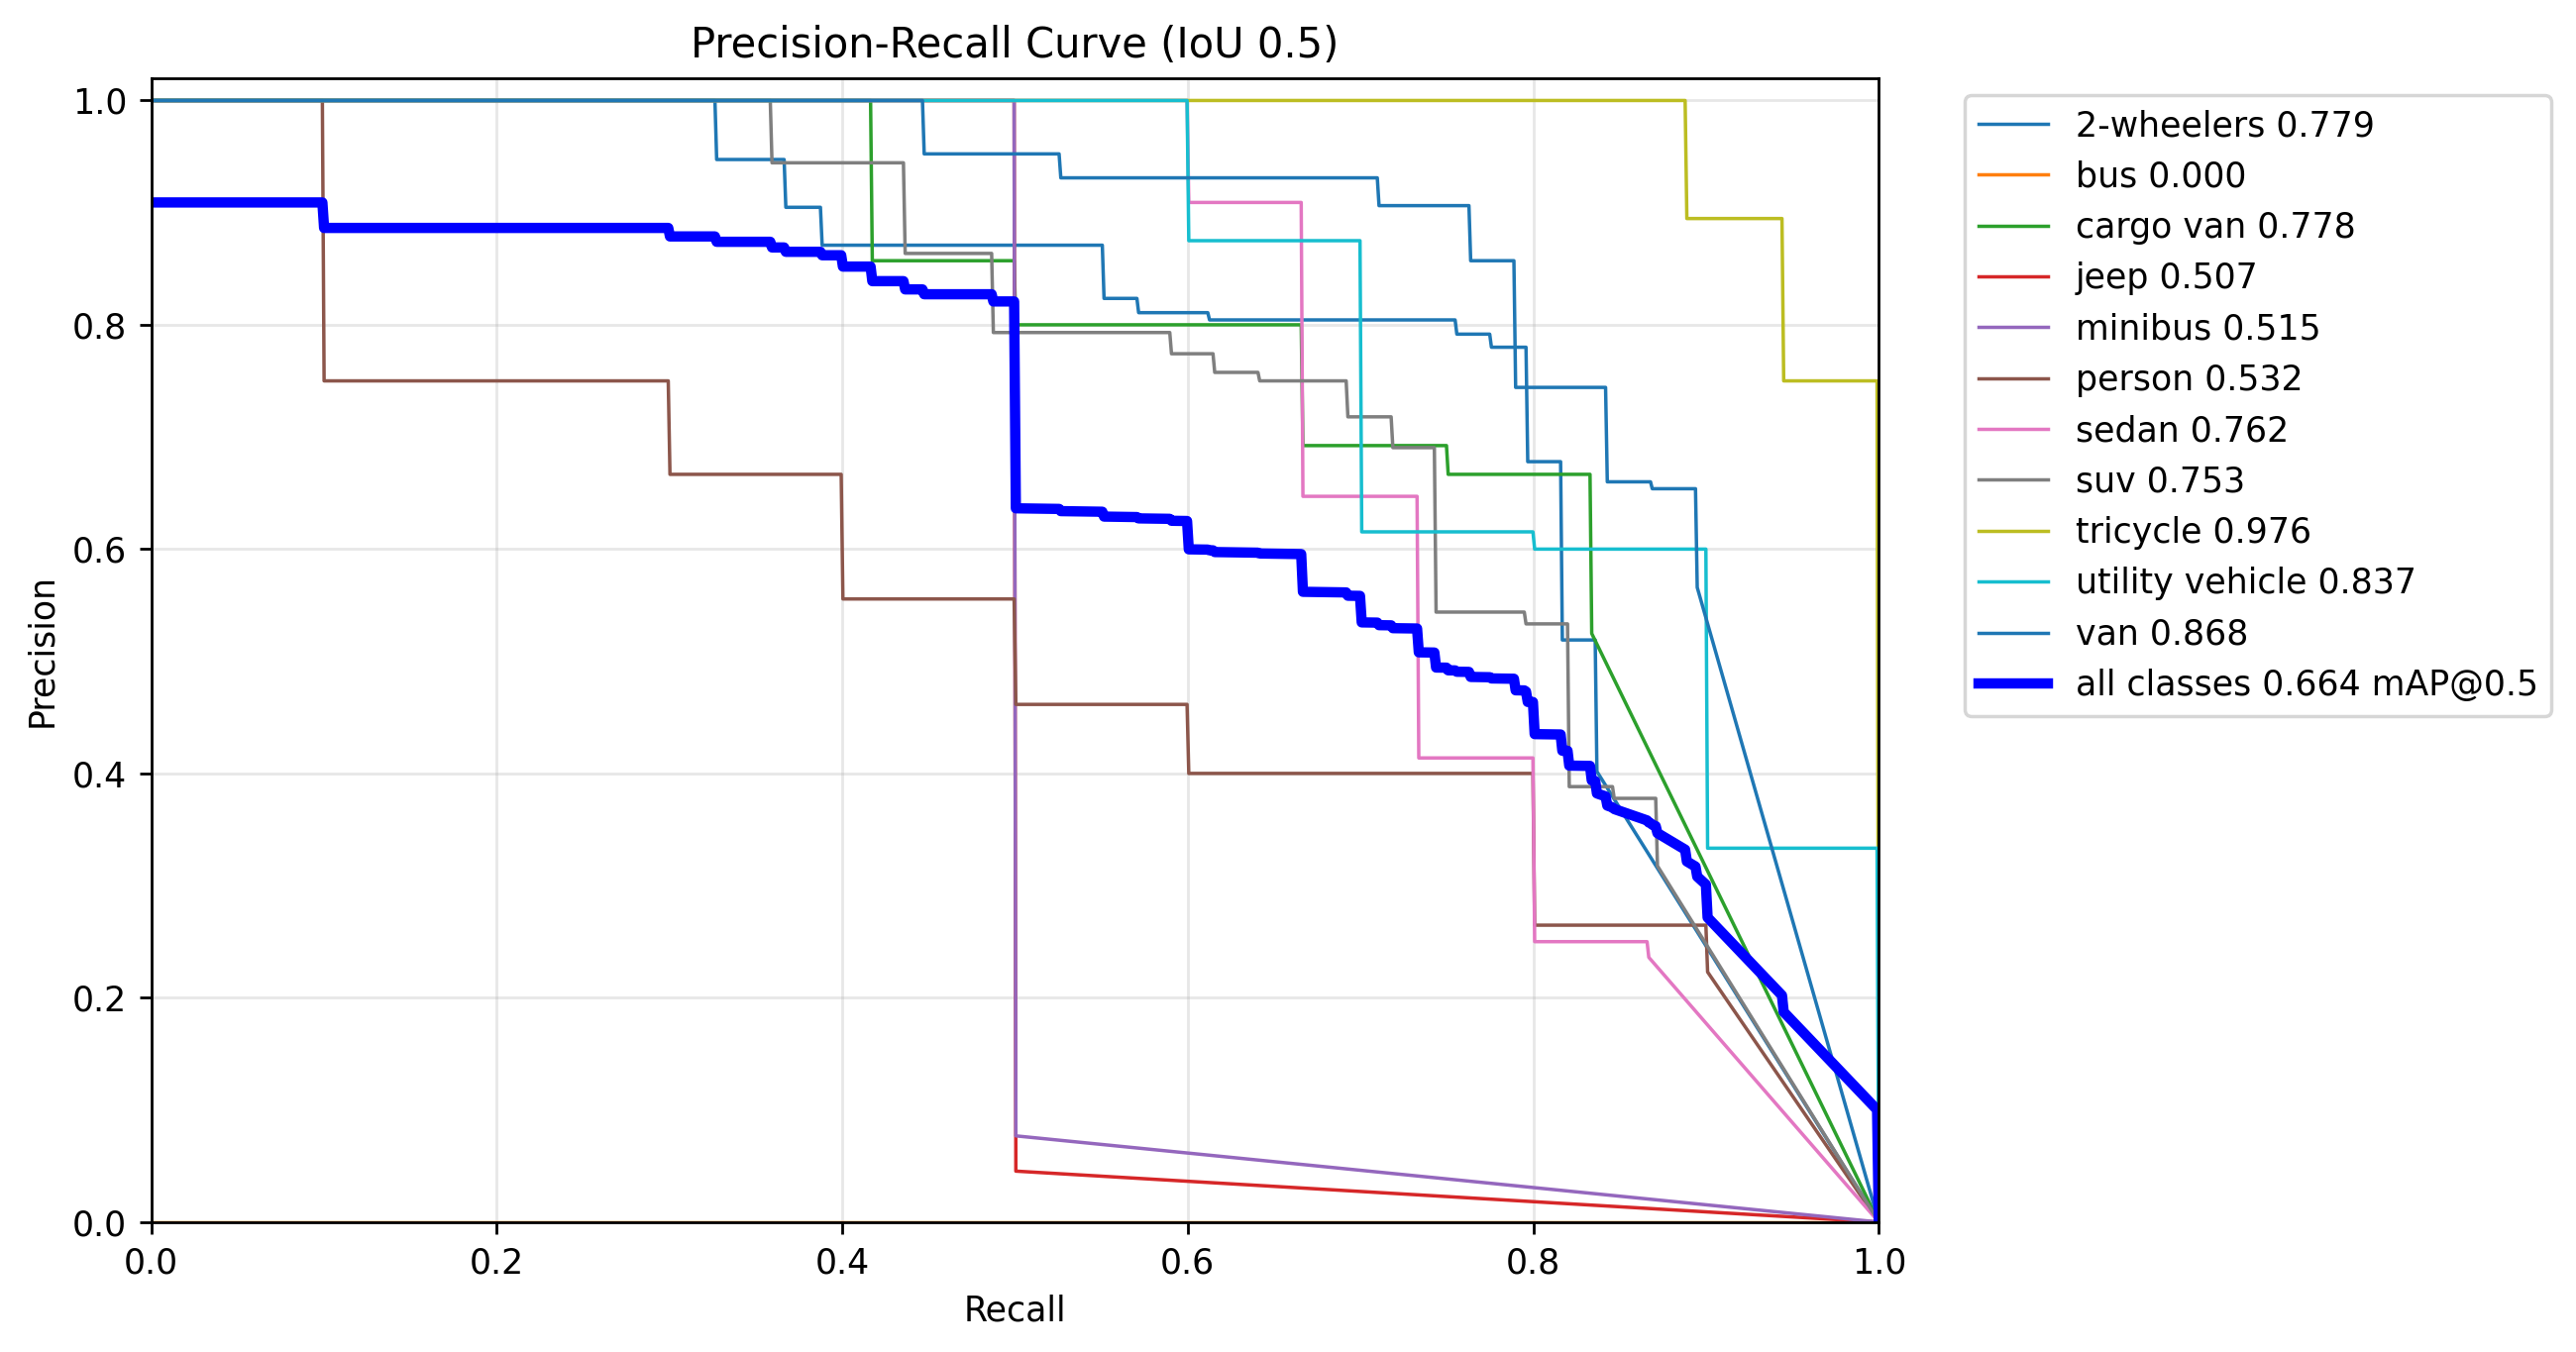

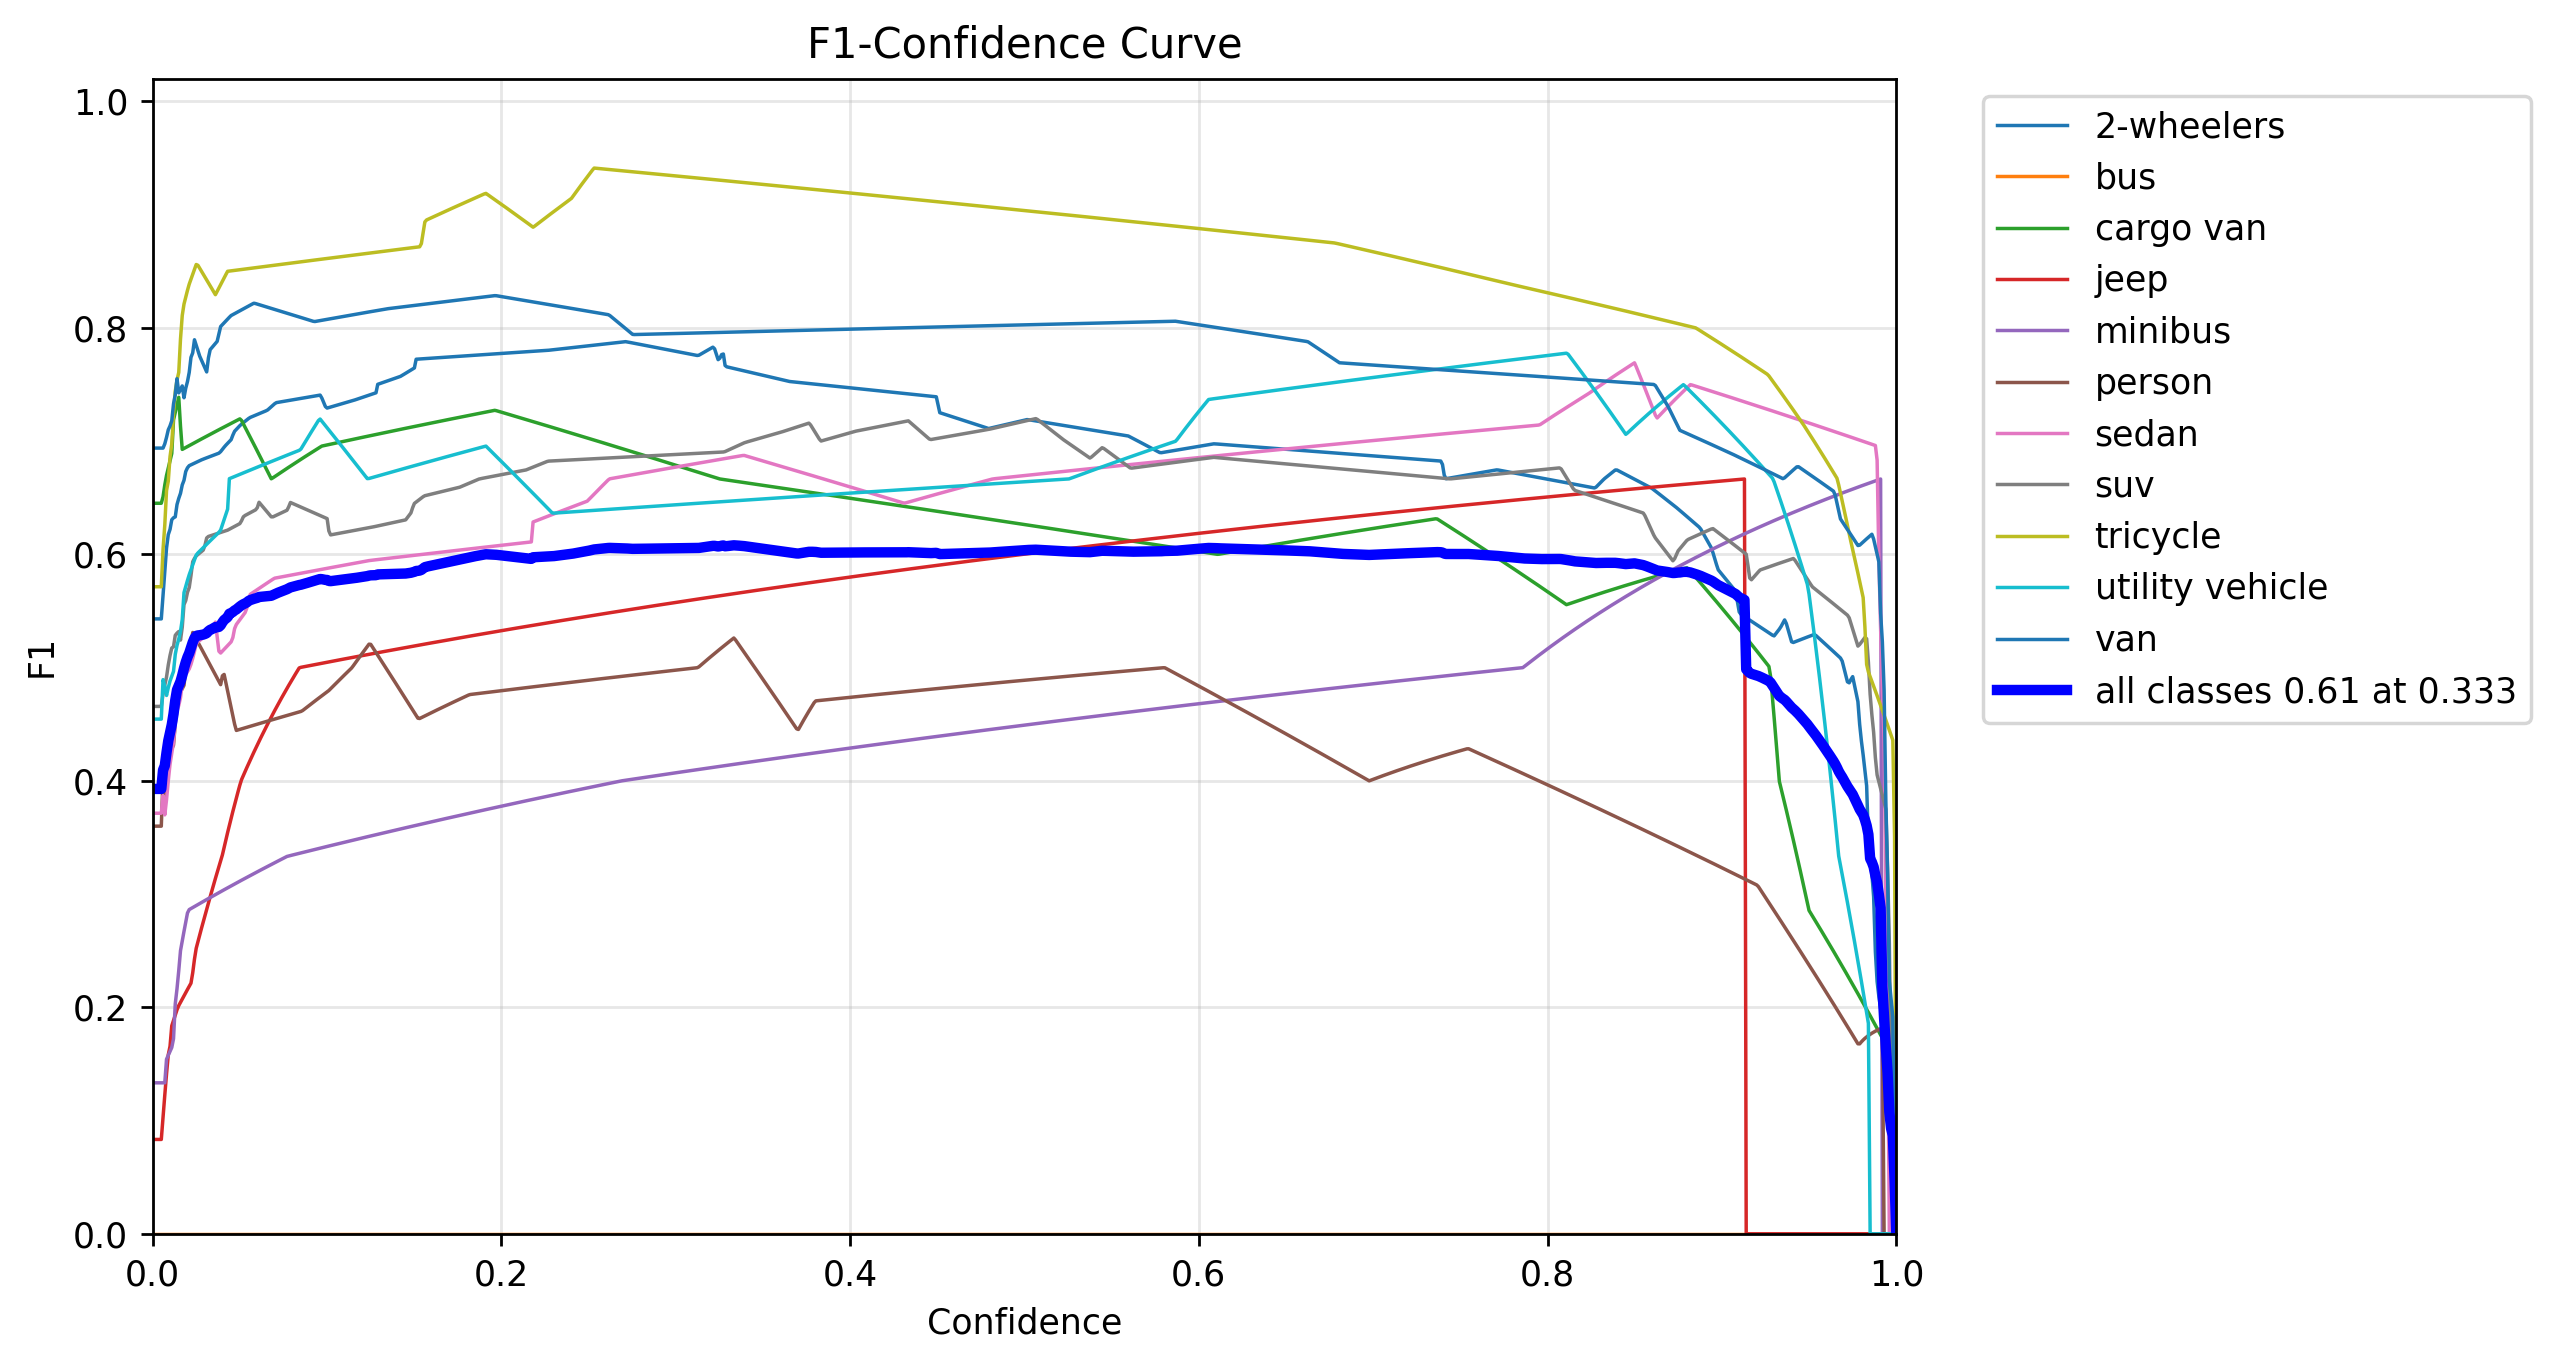

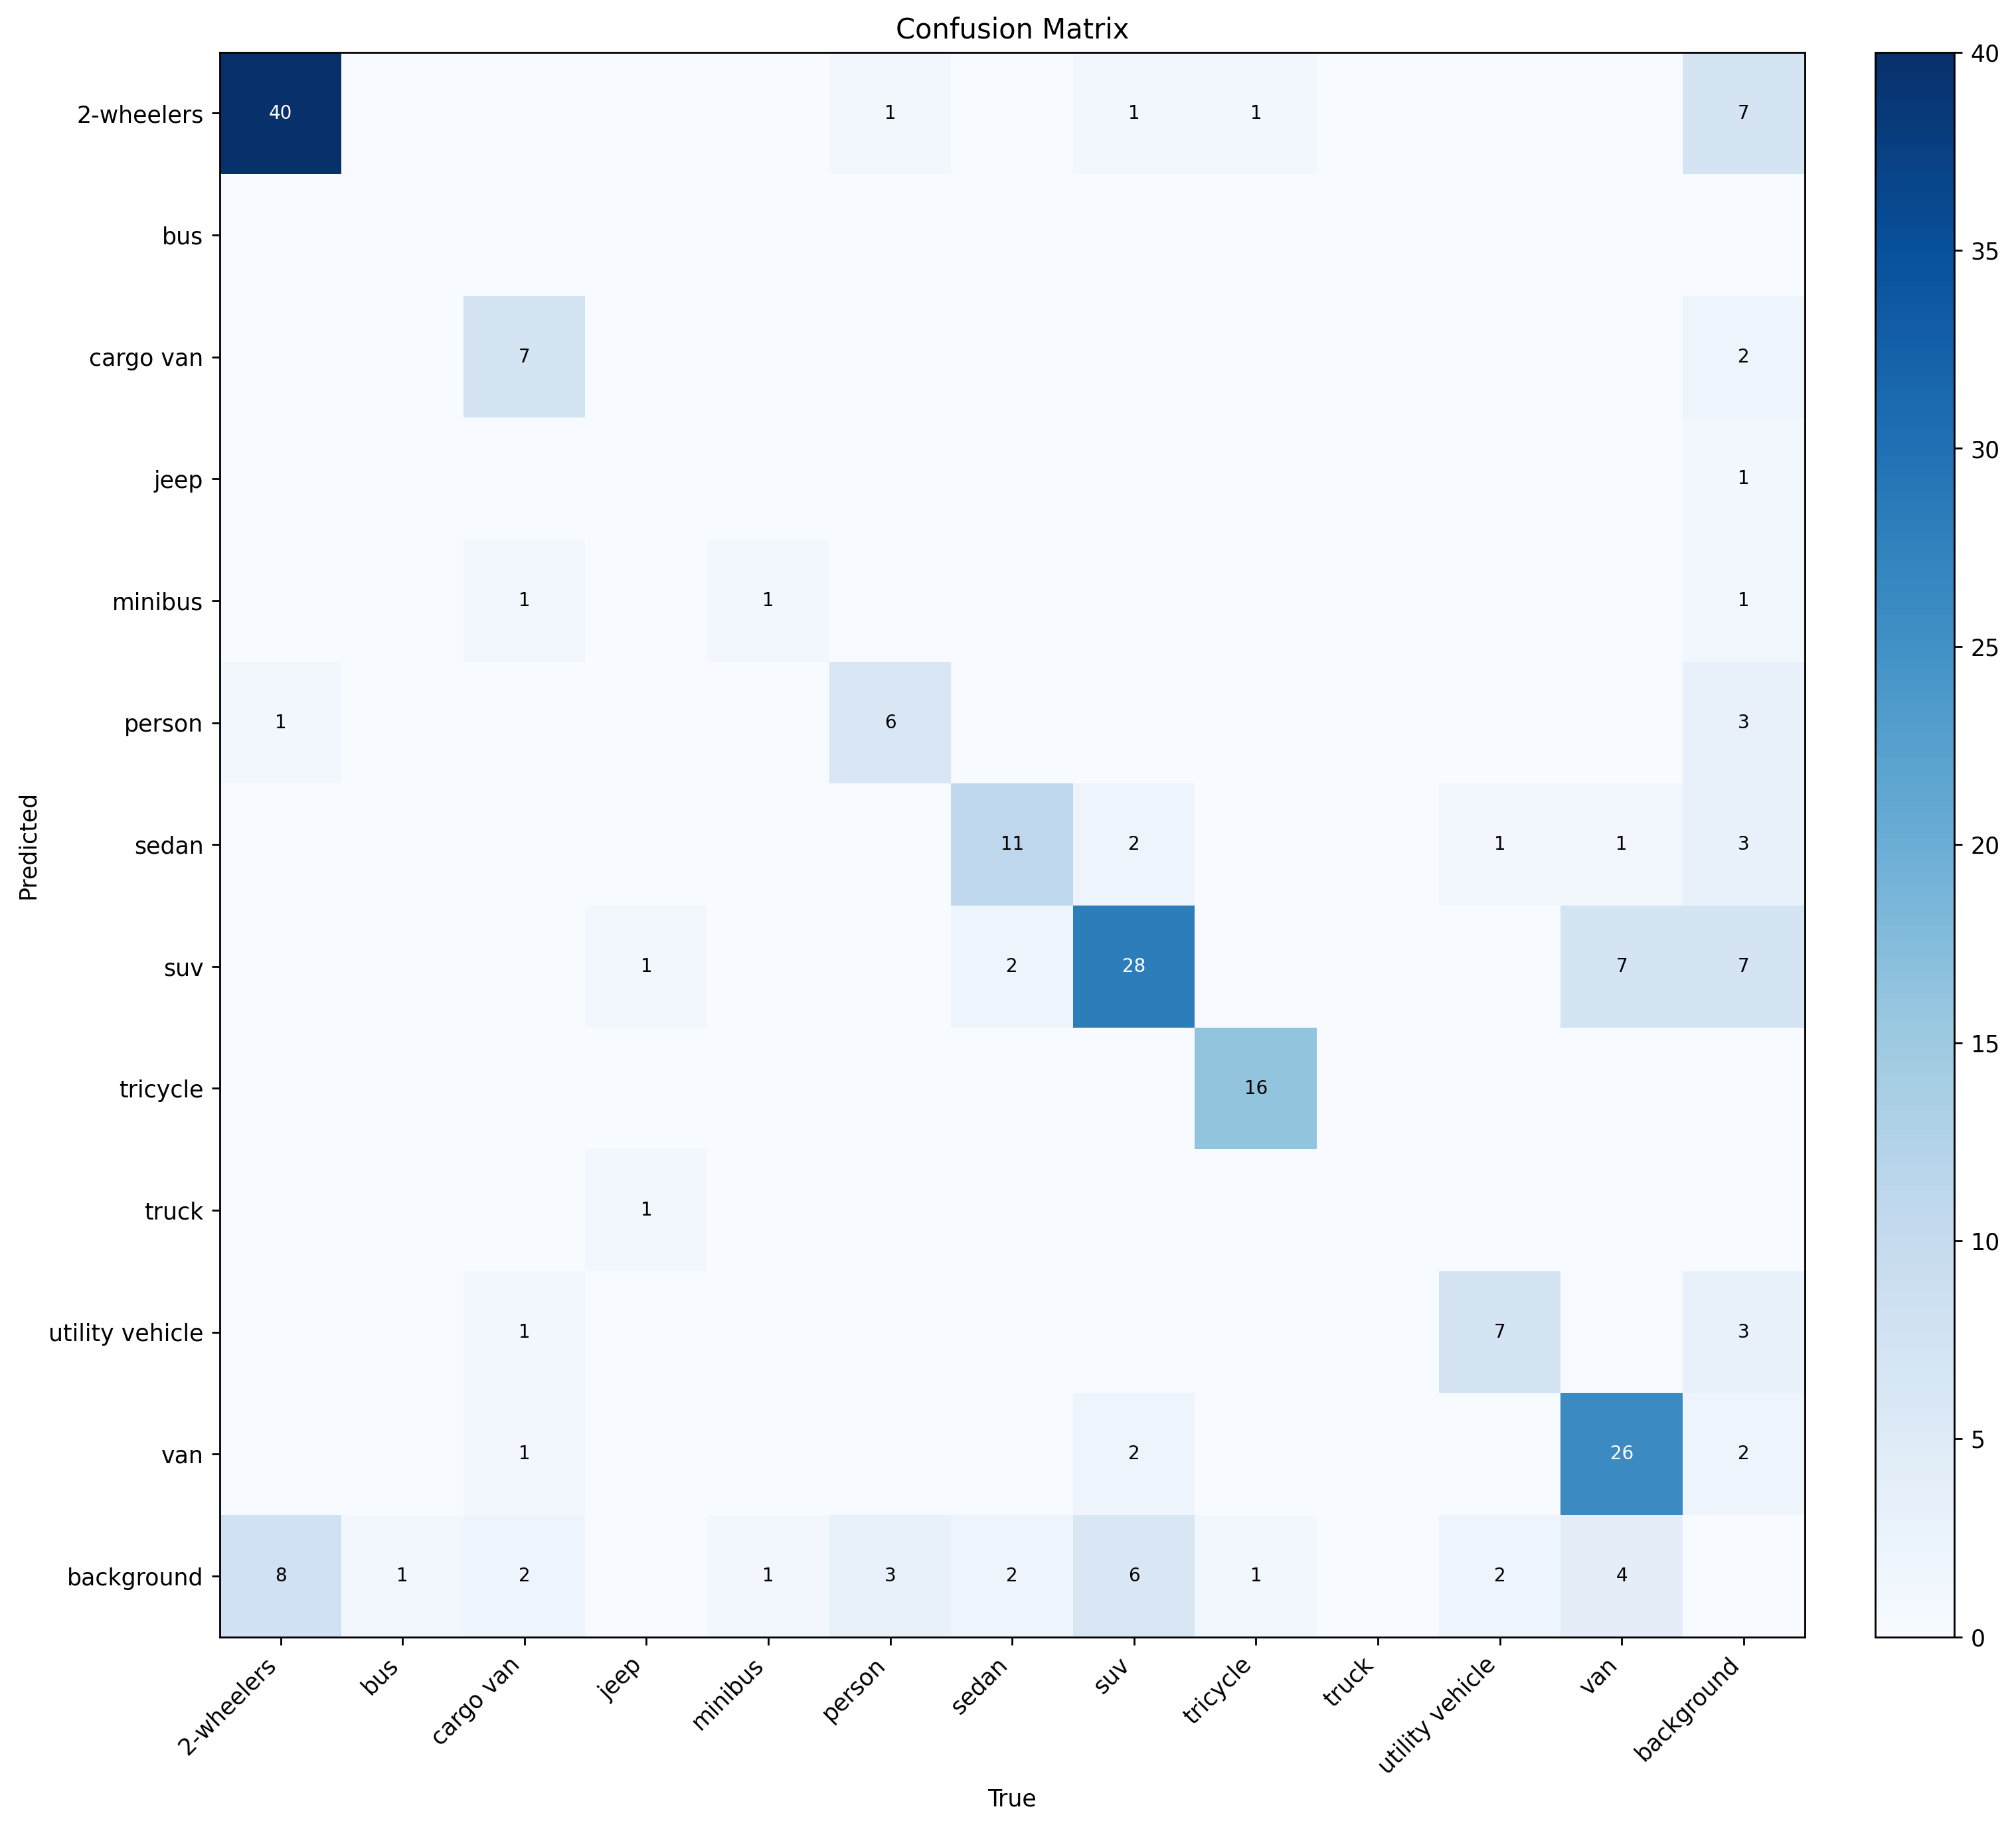

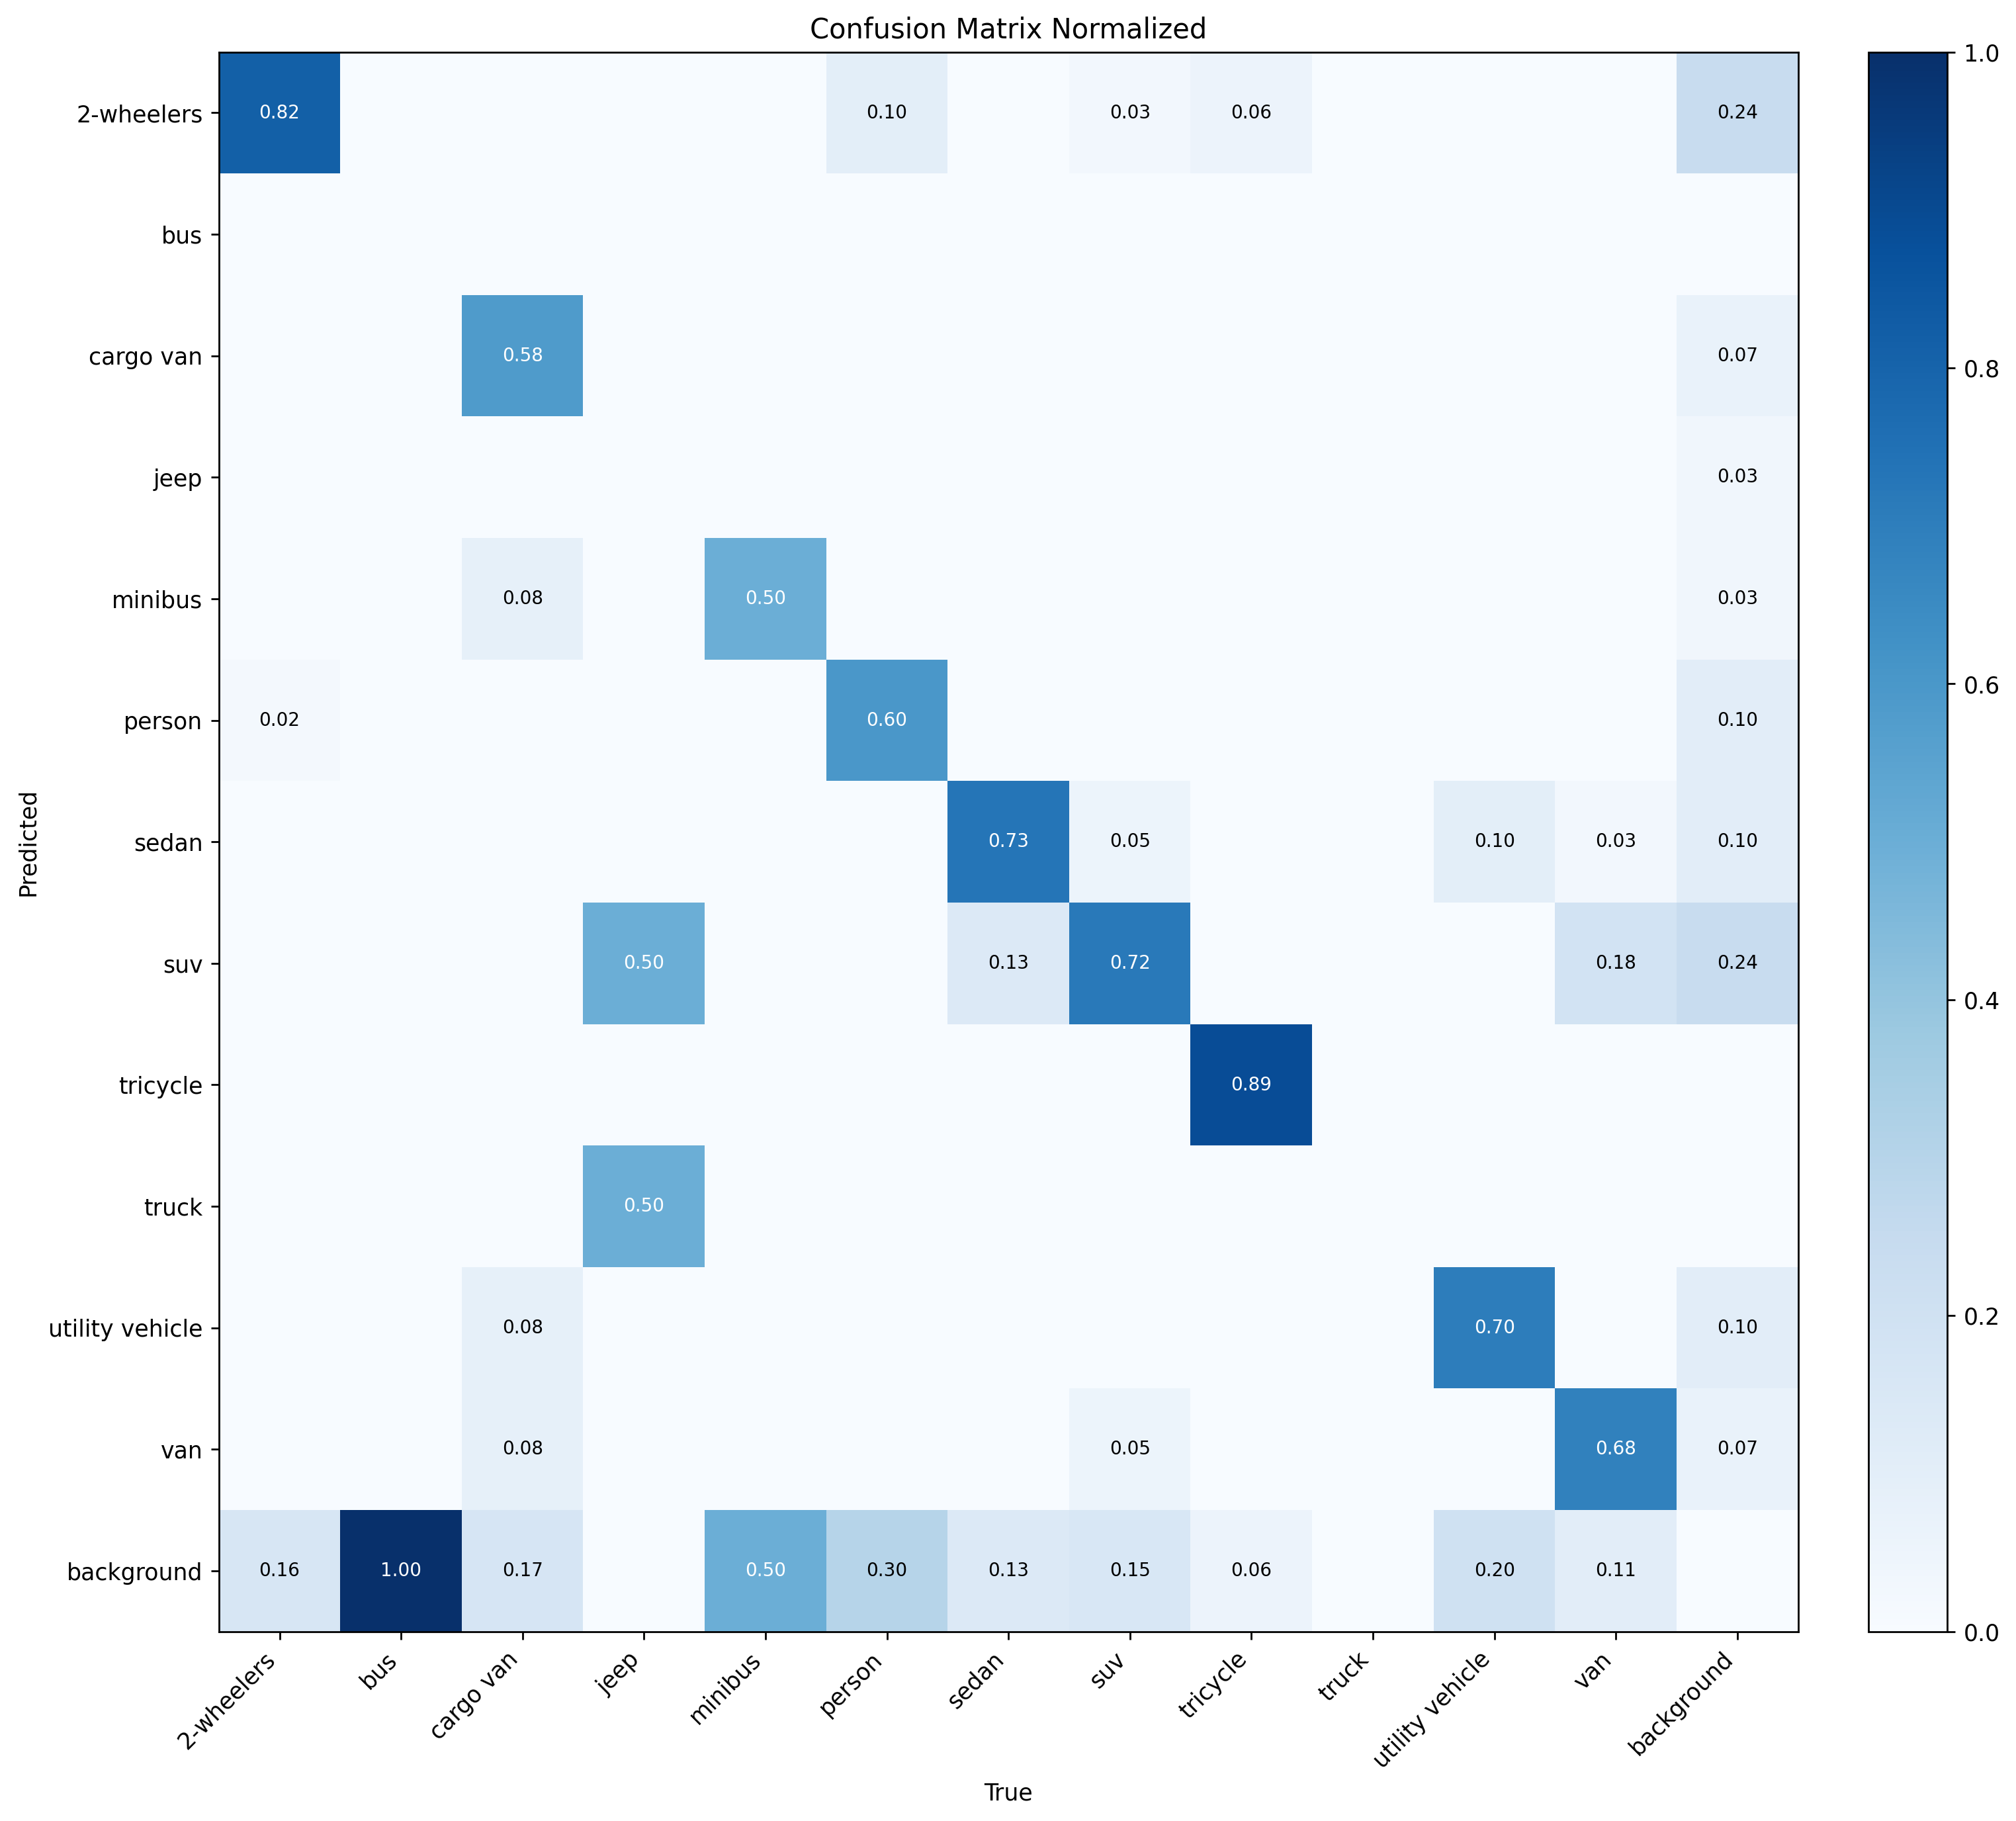

In [11]:
import os, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

IOU_THRS = np.linspace(0.5, 0.95, 10)
PX = np.linspace(0, 1, 1000)

with open('/content/darknet/data/obj.names') as f:
    names = [l.strip() for l in f if l.strip()]
nc = len(names)

# ---------- loading ----------
def read_gt(label_file):
    rows = []
    if os.path.exists(label_file):
        with open(label_file) as f:
            for line in f:
                p = line.split()
                if len(p) >= 5:
                    c = int(float(p[0]))
                    x, y, w, h = map(float, p[1:5])
                    rows.append([c, x - w / 2, y - h / 2, x + w / 2, y + h / 2])
    return np.array(rows, dtype=float).reshape(-1, 5)

def load_predictions(path):
    with open(path) as f:
        txt = f.read().strip()
    try:
        data = json.loads(txt)
    except json.JSONDecodeError:
        txt = txt.rstrip().rstrip(',')
        if not txt.endswith(']'):
            txt += '\n]'
        data = json.loads(txt)
    preds = {}
    for fr in data:
        key = os.path.splitext(os.path.basename(fr['filename']))[0]
        rows = []
        for o in fr.get('objects', []):
            rc = o['relative_coordinates']
            cx, cy, w, h = rc['center_x'], rc['center_y'], rc['width'], rc['height']
            rows.append([o['class_id'], o['confidence'], cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2])
        preds[key] = np.array(rows, dtype=float).reshape(-1, 6)
    return preds

# ---------- geometry / matching ----------
def box_iou(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0])
    iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2])
    iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)

def match_image(pred, gt):
    # pred sorted by confidence (desc); returns tp flags per IoU threshold
    tp = np.zeros((len(pred), len(IOU_THRS)), dtype=bool)
    if len(pred) == 0 or len(gt) == 0:
        return tp
    ious = box_iou(pred[:, 2:6], gt[:, 1:5]) * (pred[:, 0:1] == gt[None, :, 0])
    for k, t in enumerate(IOU_THRS):
        used = np.zeros(len(gt), dtype=bool)
        for i in range(len(pred)):
            cand = np.where(~used & (ious[i] >= t))[0]
            if len(cand):
                j = cand[np.argmax(ious[i, cand])]
                used[j] = True
                tp[i, k] = True
    return tp

def compute_ap(recall, precision):
    mrec = np.concatenate(([0.0], recall, [1.0]))
    mpre = np.concatenate(([1.0], precision, [0.0]))
    mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))
    x = np.linspace(0, 1, 101)
    y = np.interp(x, mrec, mpre)
    ap = float(np.sum((y[1:] + y[:-1]) / 2 * np.diff(x)))
    return ap, mpre, mrec

# ---------- gather everything ----------
preds_all = load_predictions('/content/darknet/result.json')
all_tp, all_conf, all_pcls, all_gcls = [], [], [], []
per_image = []
for path in eval_images:
    key = os.path.splitext(os.path.basename(path))[0]
    gt = read_gt(os.path.splitext(path)[0] + '.txt')
    pred = preds_all.get(key, np.zeros((0, 6)))
    pred = pred[np.argsort(-pred[:, 1])] if len(pred) else pred
    per_image.append((gt, pred))
    all_tp.append(match_image(pred, gt))
    all_conf.append(pred[:, 1])
    all_pcls.append(pred[:, 0].astype(int))
    all_gcls.append(gt[:, 0].astype(int))

tp = np.concatenate(all_tp) if all_tp else np.zeros((0, 10), bool)
conf = np.concatenate(all_conf)
pcls = np.concatenate(all_pcls)
gcls = np.concatenate(all_gcls)
n_gt = np.array([(gcls == c).sum() for c in range(nc)])
has_gt = n_gt > 0
print("ground-truth boxes per class:", dict(zip(names, n_gt.tolist())))
assert has_gt.any(), "No ground-truth labels found for the evaluation split."

# ---------- per-class curves and AP ----------
order = np.argsort(-conf)
tp, conf, pcls = tp[order], conf[order], pcls[order]

ap = np.zeros((nc, 10))
p_curve = np.zeros((nc, 1000)); r_curve = np.zeros((nc, 1000)); pr_curve = np.zeros((nc, 1000))
for c in range(nc):
    m = pcls == c
    if n_gt[c] == 0 or m.sum() == 0:
        continue
    tpc = np.cumsum(tp[m], axis=0)
    fpc = np.cumsum(~tp[m], axis=0)
    rec = tpc / (n_gt[c] + 1e-16)
    prec = tpc / (tpc + fpc)
    r_curve[c] = np.interp(-PX, -conf[m], rec[:, 0], left=0)
    p_curve[c] = np.interp(-PX, -conf[m], prec[:, 0], left=1)
    for j in range(len(IOU_THRS)):
        ap[c, j], mpre, mrec = compute_ap(rec[:, j], prec[:, j])
        if j == 0:
            pr_curve[c] = np.interp(PX, mrec, mpre)

f1_curve = 2 * p_curve * r_curve / (p_curve + r_curve + 1e-16)
f1_mean = f1_curve[has_gt].mean(0)
best_i = int(f1_mean.argmax())
best_conf = float(PX[best_i])

P = p_curve[:, best_i]; R = r_curve[:, best_i]; F1 = f1_curve[:, best_i]
AP50 = ap[:, 0]; AP5095 = ap.mean(1)

summary = {
    "split": eval_split,
    "images": len(eval_images),
    "operating_confidence": round(best_conf, 3),
    "precision": float(P[has_gt].mean()),
    "recall": float(R[has_gt].mean()),
    "f1": float(F1[has_gt].mean()),
    "mAP50": float(AP50[has_gt].mean()),
    "mAP50-95": float(AP5095[has_gt].mean()),
}
print(json.dumps(summary, indent=2))

# ---------- report files ----------
import csv
with open(f'{OUT}/metrics_per_class.csv', 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['class', 'gt_boxes', 'precision', 'recall', 'f1', 'mAP50', 'mAP50-95'])
    for c in range(nc):
        w.writerow([names[c], int(n_gt[c]), round(P[c], 4), round(R[c], 4), round(F1[c], 4), round(AP50[c], 4), round(AP5095[c], 4)])
    w.writerow(['all', int(n_gt.sum()), round(summary['precision'], 4), round(summary['recall'], 4),
                round(summary['f1'], 4), round(summary['mAP50'], 4), round(summary['mAP50-95'], 4)])
with open(f'{OUT}/metrics.json', 'w') as f:
    json.dump({"summary": summary,
               "per_class": {names[c]: {"gt_boxes": int(n_gt[c]), "precision": float(P[c]), "recall": float(R[c]),
                                         "f1": float(F1[c]), "mAP50": float(AP50[c]), "mAP50-95": float(AP5095[c])}
                             for c in range(nc)}}, f, indent=2)

# ---------- curves ----------
def plot_curve(x, ys, path, xlabel, ylabel, title, mean_label, per_class_labels):
    fig, ax = plt.subplots(figsize=(9, 6))
    if nc <= 20:
        for c in range(nc):
            if has_gt[c]:
                ax.plot(x, ys[c], linewidth=1, label=per_class_labels[c])
    ax.plot(x, ys[has_gt].mean(0), linewidth=3, color='blue', label=mean_label)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.legend(bbox_to_anchor=(1.04, 1), loc='upper left')
    ax.grid(alpha=0.3)
    fig.savefig(path, dpi=250, bbox_inches='tight')
    plt.close(fig)

plot_curve(PX, pr_curve, f'{OUT}/PR_curve.png', 'Recall', 'Precision', 'Precision-Recall Curve (IoU 0.5)',
           f"all classes {summary['mAP50']:.3f} mAP@0.5", [f'{names[c]} {AP50[c]:.3f}' for c in range(nc)])
plot_curve(PX, f1_curve, f'{OUT}/F1_curve.png', 'Confidence', 'F1', 'F1-Confidence Curve',
           f"all classes {f1_mean[best_i]:.2f} at {best_conf:.3f}", names)
plot_curve(PX, p_curve, f'{OUT}/P_curve.png', 'Confidence', 'Precision', 'Precision-Confidence Curve',
           f"all classes {p_curve[has_gt].mean(0).max():.2f} at 1.0", names)
plot_curve(PX, r_curve, f'{OUT}/R_curve.png', 'Confidence', 'Recall', 'Recall-Confidence Curve',
           f"all classes {r_curve[has_gt].mean(0)[0]:.2f} at 0.0", names)

# ---------- confusion matrices (conf >= 0.25, IoU >= 0.45) ----------
def build_confusion(conf_thr=0.25, iou_thr=0.45):
    cm = np.zeros((nc + 1, nc + 1))   # rows = predicted, columns = true, last index = background
    for gt, pred in per_image:
        pred = pred[pred[:, 1] >= conf_thr] if len(pred) else pred
        gc = gt[:, 0].astype(int); pc = pred[:, 0].astype(int)
        if len(gt) == 0:
            for c in pc: cm[c, nc] += 1
            continue
        if len(pred) == 0:
            for c in gc: cm[nc, c] += 1
            continue
        iou = box_iou(gt[:, 1:5], pred[:, 2:6])
        gi, pi = np.where(iou >= iou_thr)
        if len(gi):
            m = np.stack([gi, pi, iou[gi, pi]], 1)
            m = m[m[:, 2].argsort()[::-1]]
            m = m[np.unique(m[:, 1], return_index=True)[1]]
            m = m[m[:, 2].argsort()[::-1]]
            m = m[np.unique(m[:, 0], return_index=True)[1]]
        else:
            m = np.zeros((0, 3))
        mg = set(m[:, 0].astype(int).tolist()); mp = set(m[:, 1].astype(int).tolist())
        for g, p, _ in m:
            cm[pc[int(p)], gc[int(g)]] += 1
        for g in range(len(gt)):
            if g not in mg: cm[nc, gc[g]] += 1
        for p in range(len(pred)):
            if p not in mp: cm[pc[p], nc] += 1
    return cm

def plot_cm(cm, path, normalize):
    labels = names + ['background']
    mat = cm / (cm.sum(0, keepdims=True) + 1e-9) if normalize else cm
    n = len(labels)
    fig, ax = plt.subplots(figsize=(max(6, n * 0.9 + 2), max(5, n * 0.8 + 2)))
    im = ax.imshow(mat, cmap='Blues', vmin=0, vmax=1 if normalize else None)
    ax.set_xticks(range(n)); ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.set_yticks(range(n)); ax.set_yticklabels(labels)
    ax.set_xlabel('True'); ax.set_ylabel('Predicted')
    ax.set_title('Confusion Matrix Normalized' if normalize else 'Confusion Matrix')
    half = mat.max() / 2 if mat.max() > 0 else 0.5
    for i in range(n):
        for j in range(n):
            v = mat[i, j]
            if v > 0:
                ax.text(j, i, f'{v:.2f}' if normalize else f'{int(v)}', ha='center', va='center',
                        color='white' if v > half else 'black', fontsize=8)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    fig.savefig(path, dpi=250, bbox_inches='tight')
    plt.close(fig)

cm = build_confusion()
plot_cm(cm, f'{OUT}/confusion_matrix.png', normalize=False)
plot_cm(cm, f'{OUT}/confusion_matrix_normalized.png', normalize=True)

for fn in ['PR_curve.png', 'F1_curve.png', 'confusion_matrix.png', 'confusion_matrix_normalized.png']:
    display(Image(f'{OUT}/{fn}', width=620))

## 9. Darknet's own mAP report (validation split, cross-check) and extra files

In [12]:
import os, shutil, glob
os.chdir('/content/darknet')

!./darknet detector map data/obj.data cfg/custom-yolov4-tiny-detector.cfg {OUT}/best.weights > {OUT}/darknet_map_report.txt 2>&1
!tail -n 30 {OUT}/darknet_map_report.txt

for src in ['cfg/custom-yolov4-tiny-detector.cfg', 'data/obj.data', 'data/obj.names']:
    shutil.copy(src, f'{OUT}/' + os.path.basename(src))

charts = sorted(glob.glob('chart_custom-yolov4-tiny-detector.png')) or sorted(glob.glob('chart*.png'))
if charts:
    shutil.copy(charts[0], f'{OUT}/training_chart.png')
else:
    print("No training chart found (it is only created during training in this session).")

!ls -lh {OUT}

 seen 64, trained: 512 K-images (8 Kilo-batches_64) 

 calculation mAP (mean average precision)...
 Detection layer: 30 - type = 28 
 Detection layer: 37 - type = 28 

 detections_count = 1003, unique_truth_count = 340  
class_id = 0, name = 2-wheelers, ap = 67.59%   	 (TP = 47, FP = 22) 
class_id = 1, name = bus, ap = 100.00%   	 (TP = 0, FP = 0) 
class_id = 2, name = cargo van, ap = 81.91%   	 (TP = 13, FP = 5) 
class_id = 3, name = jeep, ap = 61.61%   	 (TP = 4, FP = 3) 
class_id = 4, name = minibus, ap = 100.00%   	 (TP = 3, FP = 1) 
class_id = 5, name = person, ap = 68.69%   	 (TP = 10, FP = 5) 
class_id = 6, name = sedan, ap = 64.70%   	 (TP = 29, FP = 16) 
class_id = 7, name = suv, ap = 68.71%   	 (TP = 52, FP = 38) 
class_id = 8, name = tricycle, ap = 82.20%   	 (TP = 20, FP = 4) 
class_id = 9, name = truck, ap = 0.00%   	 (TP = 0, FP = 0) 
class_id = 10, name = utility vehicle, ap = 47.38%   	 (TP = 9, FP = 6) 
class_id = 11, name = van, ap = 90.11%   	 (TP = 53, FP = 7) 

 fo

## 10. Quick inference demo

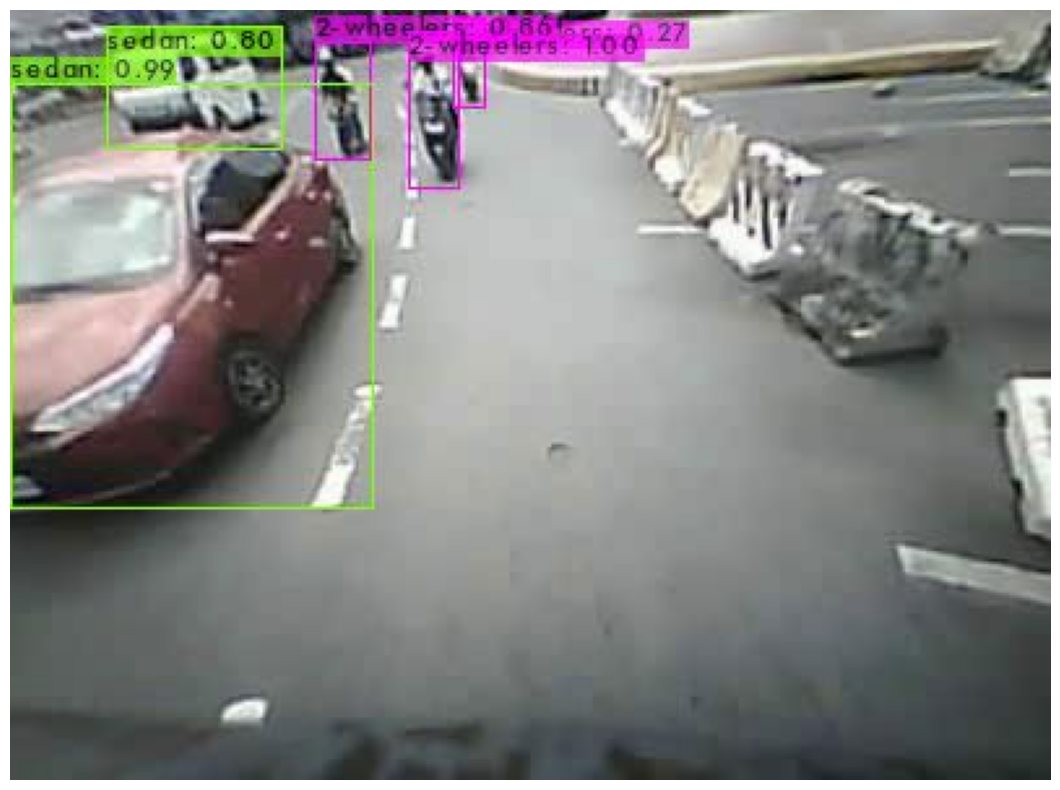

In [13]:
import os, glob, random, cv2
import matplotlib.pyplot as plt
os.chdir('/content/darknet')

img_path = random.choice(eval_images)
!./darknet detector test data/obj.data cfg/custom-yolov4-tiny-detector.cfg {OUT}/best.weights {img_path} -dont_show -thresh 0.25 > /dev/null 2>&1

img = cv2.imread('predictions.jpg')
plt.figure(figsize=(18, 10))
plt.axis('off')
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.show()

## 11. Download everything

In [14]:
from google.colab import files
import shutil

# Replace 'your_folder' with the folder you want to download
folder_name = "/content/runs/all_files"
zip_name = f"{folder_name}.zip"

# Zip the folder
shutil.make_archive(folder_name, 'zip', folder_name)

# Download the zipped folder
files.download(zip_name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>